# 01 — Análise Exploratória e Baseline

**Objetivo:** entender o dataset Telco Customer Churn (IBM), identificar problemas de qualidade,
levantar hipóteses sobre os fatores de churn, definir as métricas do projeto e treinar o
baseline com Regressão Logística.

Este notebook é de **experimentação**. O código reaproveitável (limpeza, pré-processamento,
métricas) fica nos módulos de `src/` e é importado aqui.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # permite importar o pacote src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import RANDOM_STATE, NUMERIC_FEATURES, CATEGORICAL_FEATURES

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="deep")
FIG_DIR = Path("../docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Volume e estrutura dos dados

In [2]:
from src.preprocessing import load_raw_data

raw = load_raw_data()
print(f"Linhas: {raw.shape[0]} | Colunas: {raw.shape[1]}")
raw.head()

Linhas: 7043 | Colunas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.to_frame('tipo').T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
tipo,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


## 2. Qualidade dos dados

In [4]:
print("Valores nulos por coluna:", raw.isna().sum().sum())
print("Linhas duplicadas:", raw.duplicated().sum())
print("IDs duplicados:", raw["customerID"].duplicated().sum())

# TotalCharges deveria ser numérica, mas vem como texto
total_num = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank = raw[total_num.isna()]
print(f"\nTotalCharges não numérico: {len(blank)} linhas")
blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Valores nulos por coluna: 0
Linhas duplicadas: 0
IDs duplicados: 0

TotalCharges não numérico: 11 linhas


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Achado:** os 11 registros com `TotalCharges` em branco têm `tenure = 0`, ou seja, são clientes
que acabaram de entrar e ainda não pagaram nenhuma fatura. O valor correto para eles é **0**,
e não a média ou a remoção da linha. Essa regra está em `src/preprocessing.clean_data`.

In [5]:
from src.preprocessing import clean_data

df = clean_data(raw)
df[NUMERIC_FEATURES].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 3. Distribuição do alvo

Taxa de churn: 26.5%  (1869 de 7043 clientes)


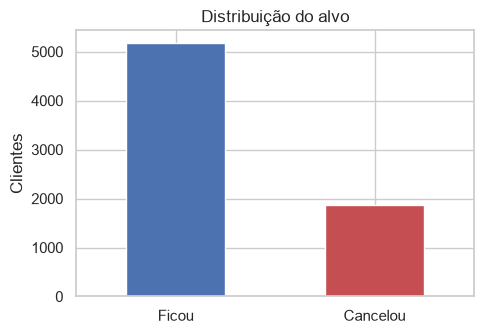

In [6]:
churn_rate = df["Churn"].mean()
print(f"Taxa de churn: {churn_rate:.1%}  ({df['Churn'].sum()} de {len(df)} clientes)")

fig, ax = plt.subplots(figsize=(5, 3.5))
df["Churn"].map({0: "Ficou", 1: "Cancelou"}).value_counts().plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_title("Distribuição do alvo"); ax.set_xlabel(""); ax.set_ylabel("Clientes")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(FIG_DIR / "target_distribution.png", dpi=120); plt.show()

**Achado:** classes desbalanceadas (~26,5% de churn). Acurácia sozinha seria enganosa:
um modelo que diz "ninguém cancela" teria ~73% de acurácia e zero utilidade. Por isso
usamos AUC-ROC, recall e F1, e tratamos o desbalanceamento com `class_weight="balanced"`
e ajuste do limiar de decisão.

## 4. Features numéricas vs churn

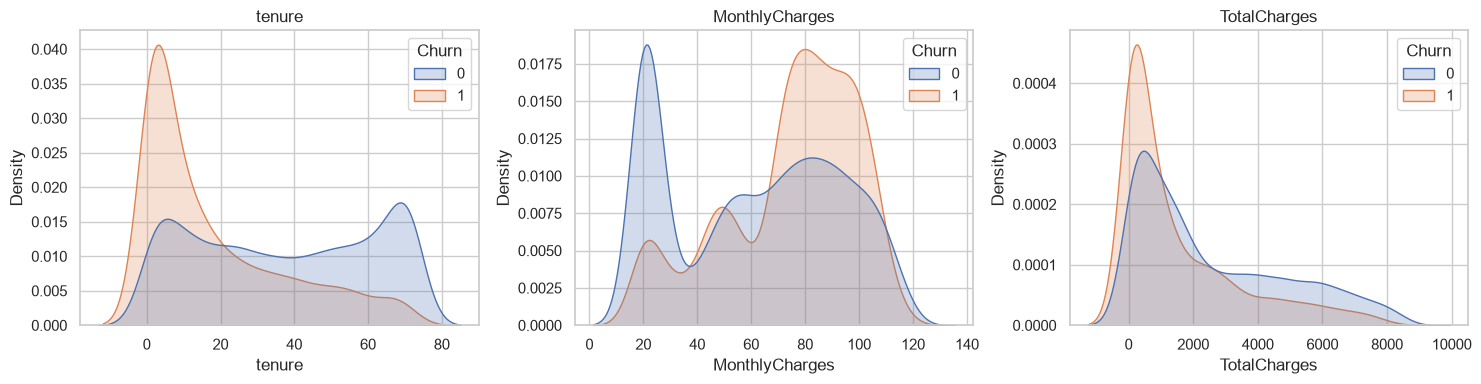

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUMERIC_FEATURES):
    sns.kdeplot(data=df, x=col, hue="Churn", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_vs_churn.png", dpi=120); plt.show()

In [8]:
df.groupby('Churn')[NUMERIC_FEATURES].median().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.43,1679.52
1,10.0,79.65,703.55


**Achados:**
- **tenure** é a variável mais discriminante: quem cancela está, em mediana, há poucos meses na empresa.
  O risco é concentrado nos primeiros meses de contrato.
- **MonthlyCharges** mais alto está associado a mais churn (planos caros, principalmente fibra).
- **TotalCharges** é quase `tenure × MonthlyCharges`, então carrega informação redundante.

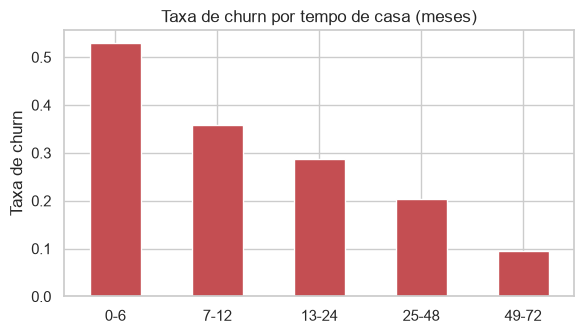

tenure_group
0-6      0.529
7-12     0.359
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn, dtype: float64

In [9]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                            labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
rate = df.groupby("tenure_group", observed=True)["Churn"].mean()
ax = rate.plot.bar(figsize=(6, 3.5), color="#C44E52")
ax.set_title("Taxa de churn por tempo de casa (meses)"); ax.set_ylabel("Taxa de churn"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG_DIR / "churn_by_tenure.png", dpi=120); plt.show()
df = df.drop(columns="tenure_group")
rate.round(3)

## 5. Features categóricas vs churn

In [10]:
rates = []
for col in CATEGORICAL_FEATURES + ["SeniorCitizen"]:
    r = df.groupby(col)["Churn"].agg(["mean", "size"]).reset_index()
    r.columns = ["categoria", "taxa_churn", "clientes"]
    r.insert(0, "feature", col)
    rates.append(r)
rates = pd.concat(rates)
# Diferença entre a maior e a menor taxa dentro de cada feature
spread = rates.groupby("feature")["taxa_churn"].agg(lambda s: s.max() - s.min()).sort_values(ascending=False)
spread.round(3).to_frame("amplitude_taxa_churn")

,amplitude_taxa_churn
feature,
Contract,0.399
InternetService,0.345
OnlineSecurity,0.344
TechSupport,0.342
OnlineBackup,0.325
DeviceProtection,0.317
PaymentMethod,0.300
StreamingMovies,0.263
StreamingTV,0.261


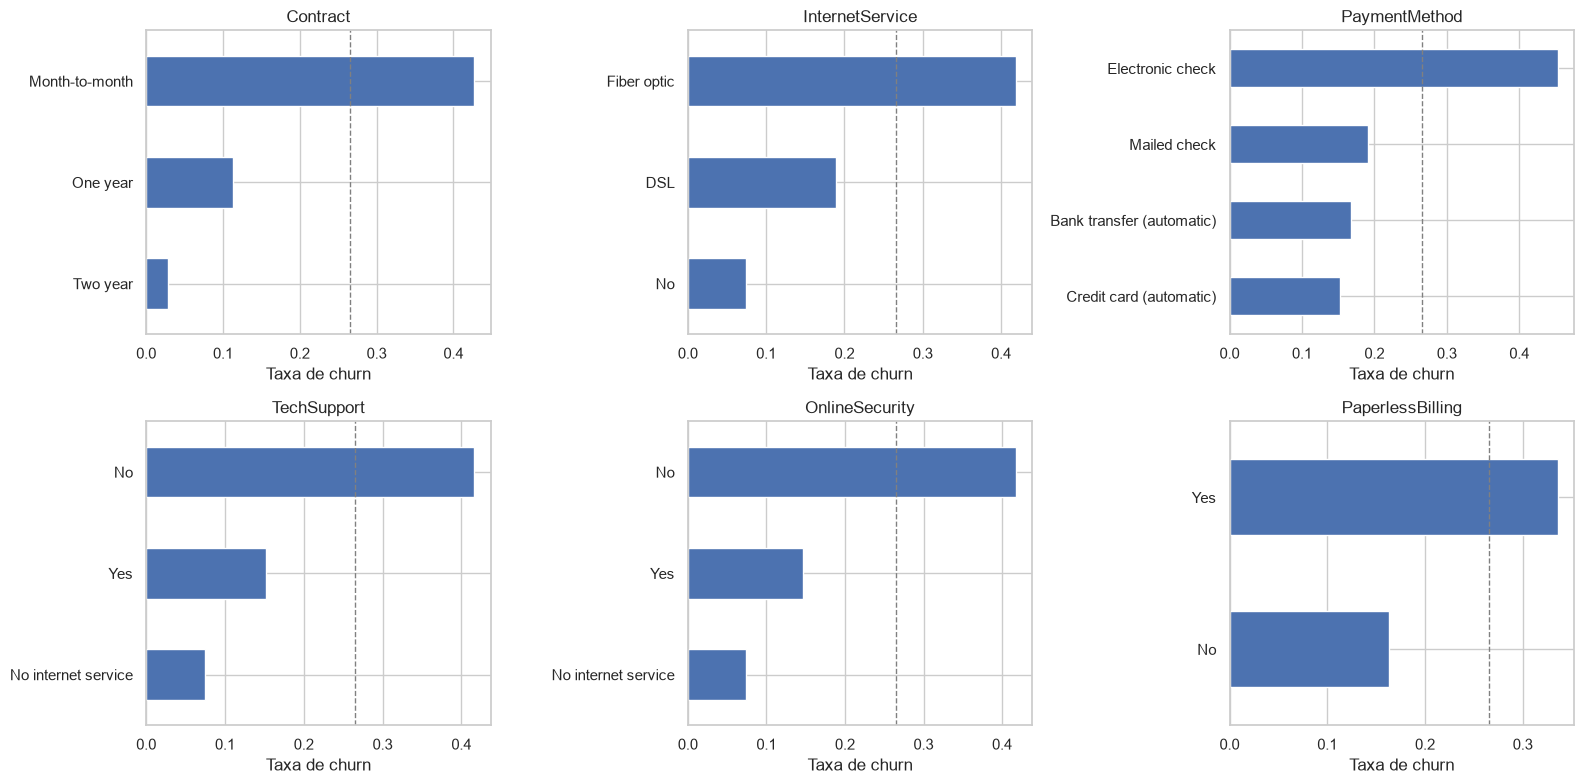

In [11]:
top = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), top):
    r = df.groupby(col)["Churn"].mean().sort_values()
    r.plot.barh(ax=ax, color="#4C72B0")
    ax.axvline(churn_rate, ls="--", c="gray", lw=1)
    ax.set_title(col); ax.set_xlabel("Taxa de churn"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "categorical_vs_churn.png", dpi=120); plt.show()

**Achados (linha tracejada = taxa média):**
- **Contract:** contrato mensal tem churn muito maior que contratos de 1 ou 2 anos. É o fator mais forte.
- **InternetService:** clientes de fibra óptica cancelam mais, apesar de ser o serviço premium
  (hipótese: preço alto ou problemas de qualidade).
- **PaymentMethod:** boleto eletrônico (*electronic check*) tem churn bem acima dos pagamentos automáticos.
- **TechSupport / OnlineSecurity:** clientes sem serviços de suporte e segurança cancelam mais.
- **gender** praticamente não muda a taxa de churn, o que é bom do ponto de vista de viés.

## 6. Correlação entre numéricas

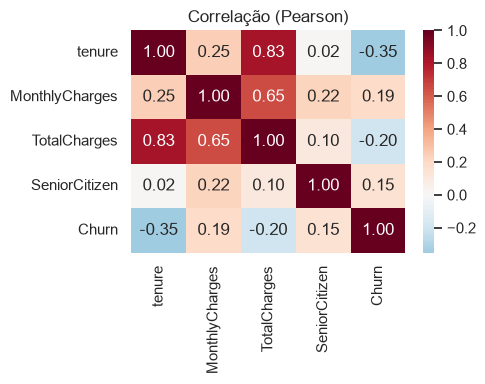

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[NUMERIC_FEATURES + ["SeniorCitizen", "Churn"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlação (Pearson)"); plt.tight_layout()
plt.savefig(FIG_DIR / "correlation.png", dpi=120); plt.show()

## 7. Definição das métricas

| Tipo | Métrica | Por quê |
|---|---|---|
| **Técnica principal** | **AUC-ROC** | Mede a capacidade de ordenar clientes por risco, independente do limiar. Robusta ao desbalanceamento. É o critério para escolher o modelo campeão. |
| Técnicas de apoio | Recall, Precision, F1 | Recall = quantos dos que cancelam o modelo encontra. Precision = quantos abordados realmente cancelariam. |
| **Negócio** | **Economia (%) vs não agir** | Custo de errar, em R$ (premissas em `src/config.py`): |

- **Falso negativo:** cliente sai sem ser abordado → perde 12 meses de mensalidade dele.
- **Verdadeiro positivo:** recebe oferta de retenção (R$ 100); 50% ficam, o resto sai mesmo assim.
- **Falso positivo:** recebe oferta sem precisar → custa R$ 100.

A economia é comparada com o cenário de **não fazer nada** (toda a receita dos que saem é perdida).
O limiar de decisão de cada modelo é escolhido para **minimizar esse custo**, usando previsões
out-of-fold do treino (o teste não é usado para nenhuma escolha).

## 8. Baseline: Regressão Logística

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from src.config import TEST_SIZE, CV_FOLDS
from src.preprocessing import split_features_target
from src.models import build_pipeline, get_models
from src.evaluation import technical_metrics, find_best_threshold

X, y = split_features_target(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")

baseline = build_pipeline(get_models()["logistic_regression"])
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(baseline, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "recall", "precision"])
pd.DataFrame({k.replace("test_", ""): v for k, v in scores.items() if k.startswith("test_")}).agg(["mean", "std"]).round(4)

Treino: (5634, 19) | Teste: (1409, 19)


,roc_auc,f1,recall,precision
mean,0.8460,0.6293,0.8027,0.5178
std,0.0139,0.0249,0.0403,0.0208


In [14]:
oof = cross_val_predict(baseline, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
threshold, curve = find_best_threshold(y_train, oof, X_train["MonthlyCharges"])
print(f"Limiar que minimiza o custo de negócio: {threshold}")

baseline.fit(X_train, y_train)
proba_test = baseline.predict_proba(X_test)[:, 1]
pd.DataFrame({
    "limiar 0.5": technical_metrics(y_test, proba_test, 0.5),
    f"limiar {threshold}": technical_metrics(y_test, proba_test, threshold),
}).round(4)

Limiar que minimiza o custo de negócio: 0.52


,limiar 0.5,limiar 0.52
roc_auc,0.8415,0.8415
f1,0.6136,0.6205
recall,0.7834,0.7781
precision,0.5043,0.5160
accuracy,0.7381,0.7473


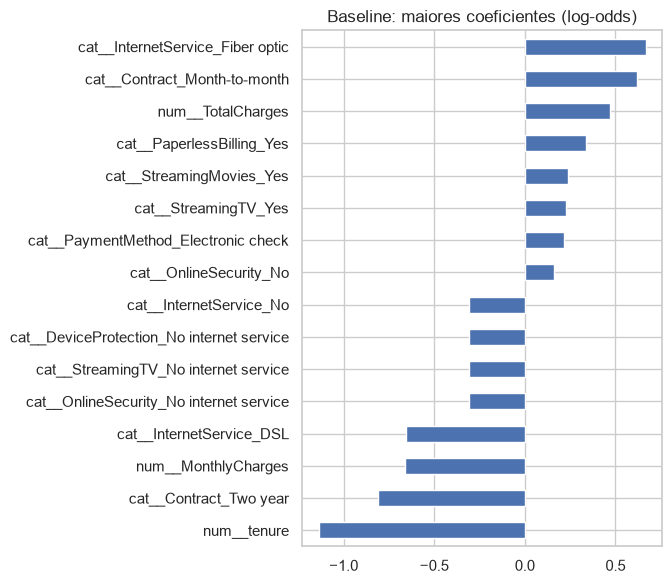

In [15]:
coefs = pd.Series(
    baseline.named_steps["model"].coef_[0],
    index=baseline.named_steps["preprocessor"].get_feature_names_out(),
).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Baseline: maiores coeficientes (log-odds)"); plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_coefficients.png", dpi=120); plt.show()

## Conclusões da Etapa 1

- Dataset limpo e com volume adequado (7.043 clientes, 19 features úteis). Único problema de
  qualidade: 11 valores em branco em `TotalCharges`, corrigidos com 0.
- Churn de ~26,5%: desbalanceado, exige métricas além da acurácia.
- Principais sinais de risco: **contrato mensal, pouco tempo de casa, fibra óptica, boleto eletrônico
  e ausência de suporte técnico**. Os coeficientes do baseline confirmam a EDA.
- O **baseline (Regressão Logística) atinge AUC ≈ 0,84** na validação cruzada. Esse é o número
  que os modelos da Etapa 2 precisam superar.